# 07MIAR — Redes Neuronales y Deep Learning
## Proyecto de programación: *Deep Vision in classification tasks*

**Actividad:** Comparación de estrategias para la clasificación de imágenes

**Autor(es):** Adelso Steve Araya Solórzano - Fabio Antonio Rodriguez Quesada - Bhuvana Cheemala

**Dataset:** Human Action Recognition (HAR) Dataset   https://www.kaggle.com/datasets/meetnagadia/human-action-recognition-har-dataset

**Problema de clasificación**

## Índice

1. Planteamiento del problema y selección del dataset
2. Carga de datos
3. Inspección y análisis exploratorio
4. Acondicionamiento y preprocesamiento
5. Estrategia 1 - CNN desde cero (*from scratch*)
6. Estrategia 2 - Modelos preentrenados (*transfer learning* y *fine-tuning*)
7. Evaluación y comparación global
8. Conclusiones
9. Referencias y exportación a PDF

**Requisito central:** comparar una CNN entrenada desde cero con, al menos, dos arquitecturas preentrenadas sobre ImageNet. Justificar experimentalmente las decisiones y evaluar finalmente sobre datos no utilizados durante el entrenamiento.

# 1. Planteamiento del problema y selección del dataset

## 1.1 Descripción del problema

**Problema de clasificación:** El problema que se presenta es la identificación de 15 clases de acciones humanas (Human Action Recognition) a partir de imágenes fijas, donde cada imagen muestra a una o varias personas realizando una actividad cotidiana.

**Aplicación o motivación:** La clasificación de imágenes mediante técnicas de Deep Learning representa una herramienta de gran potencial para automatizar tareas de reconocimiento y análisis visual. La motivación de este proyecto es explorar cómo diferentes arquitecturas de redes neuronales pueden aprender a identificar patrones y clasificar imágenes, comparando el rendimiento de modelos construidos desde cero con modelos preentrenados mediante Transfer Learning. Con ello, se busca comprender las ventajas y limitaciones de cada enfoque, así como evaluar cómo influyen las distintas técnicas de entrenamiento y optimización en la precisión y capacidad de generalización de los modelos.

**Variable objetivo y significado de las clases:** Cada clase identifica un tipo de actividad humana. Las clases que contiene el dataset son:

| Clase | Descripción |
|-------|-------------|
| 0     | calling     |
| 1     | clapping    |
| 2     | cycling     |
| 3     | dancing     |
| 4     | drinking    |
| 5     | eating      |
| 6     | fighting    |
| 7     | hugging     |
| 8     | laughing    |
| 9     | listening_to_music     |
| 10    | running     |
| 11    | sitting     |
| 12    | sleeping    |
| 13    | texting     |
| 14    | using_laptop|


## 1.2 Dataset seleccionado

- **Características principales:** conjunto de fotografías reales en color (no sintéticas ni en escala de grises) que muestran a una o varias personas realizando 15 actividades cotidianas distintas, en escenarios, fondos, poses e iluminación muy variables. Procede de una competición pública de Kaggle y ya viene dividido en entrenamiento y test.
- Nombre: Human Action Recognition (HAR)
- Fuente y enlace: (https://www.kaggle.com/datasets/meetnagadia/human-action-recognition-har-dataset)
- Estructura de directorios y etiquetas: **TEST:** Dataset/HumanActionRecognition/Testing_set.csv  **TRAINING:** Dataset/HumanActionRecognition/Training_set.csv . Adicionalmente, existen dos carpetas con las imagenes individuales de cada clase en el directorio Dataset/HumanActionRecognition/train/ y Dataset/HumanActionRecognition/test/ respectivamente.
- Número total de imágenes: 18000 (training data 12600) (test data 5400, sin etiqueta de clase)
- Número de clases: 15 clases
- **Distribución de clases:** el conjunto de entrenamiento está perfectamente balanceado, con exactamente 840 imágenes por clase (15 × 840 = 12600). No existe, por tanto, desequilibrio de clases que deba corregirse.
- **Dimensiones y formatos de imagen:** todas las imágenes están en formato RGB (3 canales), pero con dimensiones variables. Sobre una muestra de 300 imágenes del conjunto de entrenamiento, el ancho varía entre 96 y 396 píxeles y el alto entre 84 y 301 píxeles (media aproximada: 260×196 px). Por ello es necesario redimensionar todas las imágenes a un tamaño común (por ejemplo, 128x128) antes de entrenar los modelos.

## 1.3 Justificación de la elección

El dataset HAR resulta adecuado para este proyecto por varias razones. En primer lugar, se trata de un problema de clasificación de imágenes con una variable objetivo claramente definida (15 clases de actividades humanas) y con un volumen de datos suficiente (12600 imágenes de entrenamiento) para entrenar y comparar modelos de Deep Learning. En segundo lugar, el conjunto está perfectamente balanceado entre clases, lo que permite evaluar el rendimiento de los modelos sin necesidad de aplicar técnicas de corrección de desbalanceo, aislando así el efecto de las decisiones de arquitectura y entrenamiento. Por último, al tratarse de imágenes reales (no sintéticas) con fondos, poses, iluminación y encuadres variables, el dataset presenta una complejidad visual mayor que otros conjuntos más sencillos (como MNIST o Sign Language MNIST), lo que permite ilustrar de forma más clara las ventajas del *transfer learning* frente a una CNN entrenada desde cero con un número limitado de datos.


In [23]:
# 1.4 Configuración inicial e importaciones
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt
import cv2

# Semillas para favorecer la reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Parámetros generales del proyecto
IMG_SIZE = (128, 128)      # tamaño al que se redimensionarán todas las imágenes
BATCH_SIZE = 32
KAGGLE_DATASET = "meetnagadia/human-action-recognition-har-dataset"


# 2. Carga del conjunto de datos

## 2.1 Descarga y preparación inicial

El dataset se descarga directamente desde Kaggle mediante la librería `kagglehub` (ver celda siguiente), tal y como recomienda el enunciado, en lugar de subir manualmente los ficheros.

## 2.2 Organización de los datos

El dataset está organizado, dentro de la ruta local devuelta por `kagglehub`, de la siguiente forma:

- `Training_set.csv`: contiene, para cada imagen de entrenamiento, su nombre de fichero (`filename`) y su etiqueta de clase (`label`).
- `Testing_set.csv`: contiene únicamente el nombre de fichero (`filename`) de las imágenes de test; **no incluye la etiqueta de clase**, por lo que no puede utilizarse para calcular métricas de evaluación.
- `train/`: carpeta con las 12600 imágenes de entrenamiento en formato JPG, referenciadas por `filename` en `Training_set.csv`.
- `test/`: carpeta con las 5400 imágenes de test (sin etiqueta) en formato JPG, referenciadas en `Testing_set.csv`.

Dado que el test de Kaggle no está etiquetado, la evaluación final del modelo (sección 6) se realizará sobre una partición de test obtenida internamente a partir del conjunto de entrenamiento etiquetado (por ejemplo, train/validación/test con una proporción como 70/15/15), tal y como se detalla en la sección 4 de acondicionamiento.


In [24]:
# COMPLETAR: definir rutas y descargar/preparar el dataset.
# COMPLETAR: implementar, si resulta conveniente, una función reutilizable
# para automatizar la descarga y preparación inicial.
# COMPLETAR: comprobar que las rutas y los ficheros esperados existen.

# pip install kagglehub
import kagglehub

def descargar_dataset_har(handle: str = KAGGLE_DATASET) -> str:
    """
    Descarga el dataset Human Action Recognition desde Kaggle Hub
    (o reutiliza la copia ya cacheada localmente si ya se descargó antes)
    y devuelve la ruta local donde quedan disponibles los CSV y las
    carpetas de imágenes.

    Requiere credenciales de Kaggle configuradas (ver sección 2.1).
    """
    ruta_local = kagglehub.dataset_download(handle)
    print("Dataset disponible en:", ruta_local)
    return ruta_local

# NOTA: kagglehub descomprime el .zip de Kaggle tal cual, y este dataset en
# concreto contiene una carpeta intermedia llamada "Human Action Recognition"
# antes de llegar a los CSV y a las carpetas train/test. Lo comprobamos con
# os.listdir para no depender de un nombre de carpeta fijo.
ruta_descarga = descargar_dataset_har()
subcarpetas = [d for d in os.listdir(ruta_descarga)
               if os.path.isdir(os.path.join(ruta_descarga, d))]
assert len(subcarpetas) == 1, f"Se esperaba una única subcarpeta, se encontraron: {subcarpetas}"
BASE_PATH = os.path.join(ruta_descarga, subcarpetas[0])
print("Carpeta base del dataset:", BASE_PATH)

# Rutas derivadas de la ruta base descargada por kagglehub
TRAIN_CSV = os.path.join(BASE_PATH, "Training_set.csv")
TEST_CSV = os.path.join(BASE_PATH, "Testing_set.csv")
TRAIN_DIR = os.path.join(BASE_PATH, "train")
TEST_DIR = os.path.join(BASE_PATH, "test")

for ruta in [TRAIN_CSV, TEST_CSV, TRAIN_DIR, TEST_DIR]:
    assert os.path.exists(ruta), f"No se encontró la ruta esperada: {ruta}"

print("Rutas del dataset verificadas correctamente.")


Dataset disponible en: /Users/bhuvanacheemala/.cache/kagglehub/datasets/meetnagadia/human-action-recognition-har-dataset/versions/1
Carpeta base del dataset: /Users/bhuvanacheemala/.cache/kagglehub/datasets/meetnagadia/human-action-recognition-har-dataset/versions/1/Human Action Recognition
Rutas del dataset verificadas correctamente.


In [25]:
# COMPLETAR: cargar los datos y obtener los conjuntos de entrenamiento,
# y test.
# Registrar el número de imágenes y clases de cada partición.

# Entrenamiento (con etiqueta)
df_train = pd.read_csv(TRAIN_CSV)
X_train = df_train.drop('label', axis=1)
y_train = df_train['label']

# Test (sin etiqueta, proporcionado por Kaggle)
df_test = pd.read_csv(TEST_CSV)
X_test = df_test

print(f"Imágenes de entrenamiento: {X_train.shape[0]}")
print(f"Imágenes de test (sin etiqueta): {X_test.shape[0]}")
print(f"Número de clases en entrenamiento: {y_train.nunique()}")
# El desglose por clase se analiza en detalle en la sección 3.1.


Imágenes de entrenamiento: 12600
Imágenes de test (sin etiqueta): 5400
Número de clases en entrenamiento: 15


# 3. Inspección y análisis exploratorio de los datos

## 3.1 Distribución de clases

[COMPLETAR: analizar el número de imágenes por clase e identificar posibles desequilibrios.]

Task was destroyed but it is pending!
task: <Task pending name='Task-538' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/bhuvanacheemala/MIAR/.venv/lib/python3.13/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-539' coro=<Kernel.shell_main() running at /Users/bhuvanacheemala/MIAR/.venv/lib/python3.13/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/bhuvanacheemala/MIAR/.venv/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py:563]>
Exception ignored in: <coroutine object Kernel.shell_main at 0x12c535040>
Traceback (most recent call last):
  File "<string>", line 1, in <lambda>
KeyError: '__import__'
Exception ignored in: <coroutine object Kernel.shell_main at 0x12c535040>
Traceback (most recent call last):
  File "<string>", line 1, in <lambda>
KeyError: '__import__'
Task was destroyed but it is pending!
task: <Task pending name='Task-539' coro=<Kernel.sh

Número de imágenes por clase (entrenamiento):
label
calling               840
clapping              840
cycling               840
dancing               840
drinking              840
eating                840
fighting              840
hugging               840
laughing              840
listening_to_music    840
running               840
sitting               840
sleeping              840
texting               840
using_laptop          840
Name: count, dtype: int64


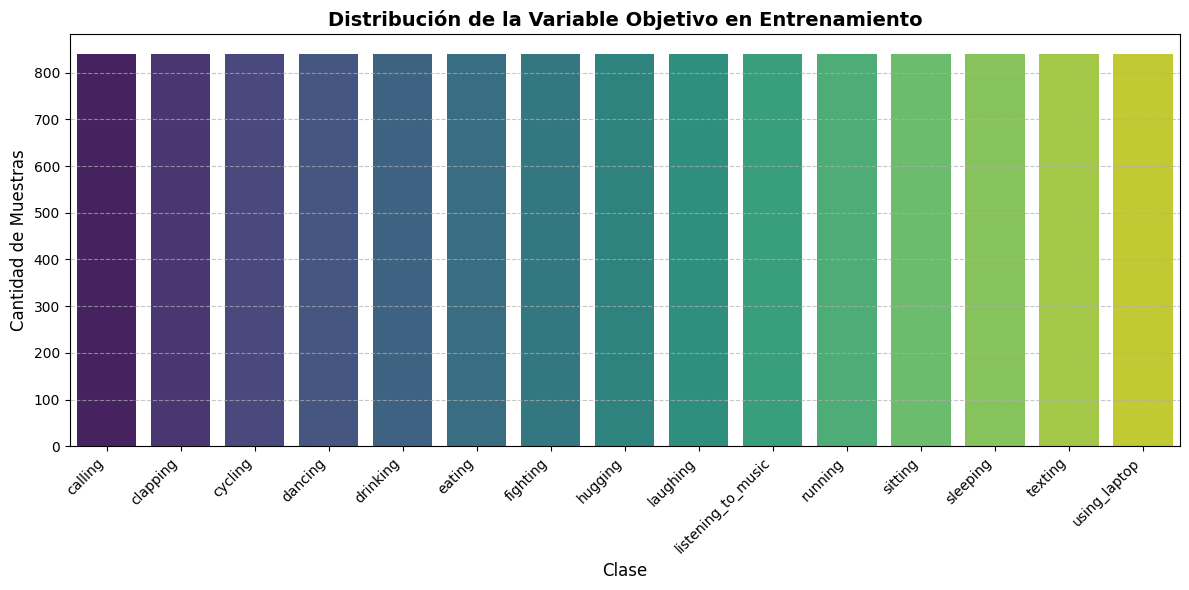

In [26]:
# COMPLETAR: calcular el número de imágenes por clase.
# COMPLETAR: representar gráficamente la distribución de clases.

conteo_clases = y_train.value_counts().sort_index()
print("Número de imágenes por clase (entrenamiento):")
print(conteo_clases)

df_plot = conteo_clases.reset_index()
df_plot.columns = ["clase", "cantidad"]

plt.figure(figsize=(12, 6))
sns.barplot(
    x="clase",
    y="cantidad",
    hue="clase",
    data=df_plot,
    order=df_plot["clase"],
    palette="viridis",
    legend=False,
)

plt.title(
    "Distribución de la Variable Objetivo en Entrenamiento",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Clase", fontsize=12)
plt.ylabel("Cantidad de Muestras", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


## 3.2 Inspección visual de imágenes

Se muestran dos imágenes de ejemplo por cada una de las 15 clases, tal y como se hace en el notebook de referencia de la asignatura. Esto permite detectar visualmente problemas de calidad, variabilidad o posibles errores de etiquetado antes de diseñar el preprocesamiento.

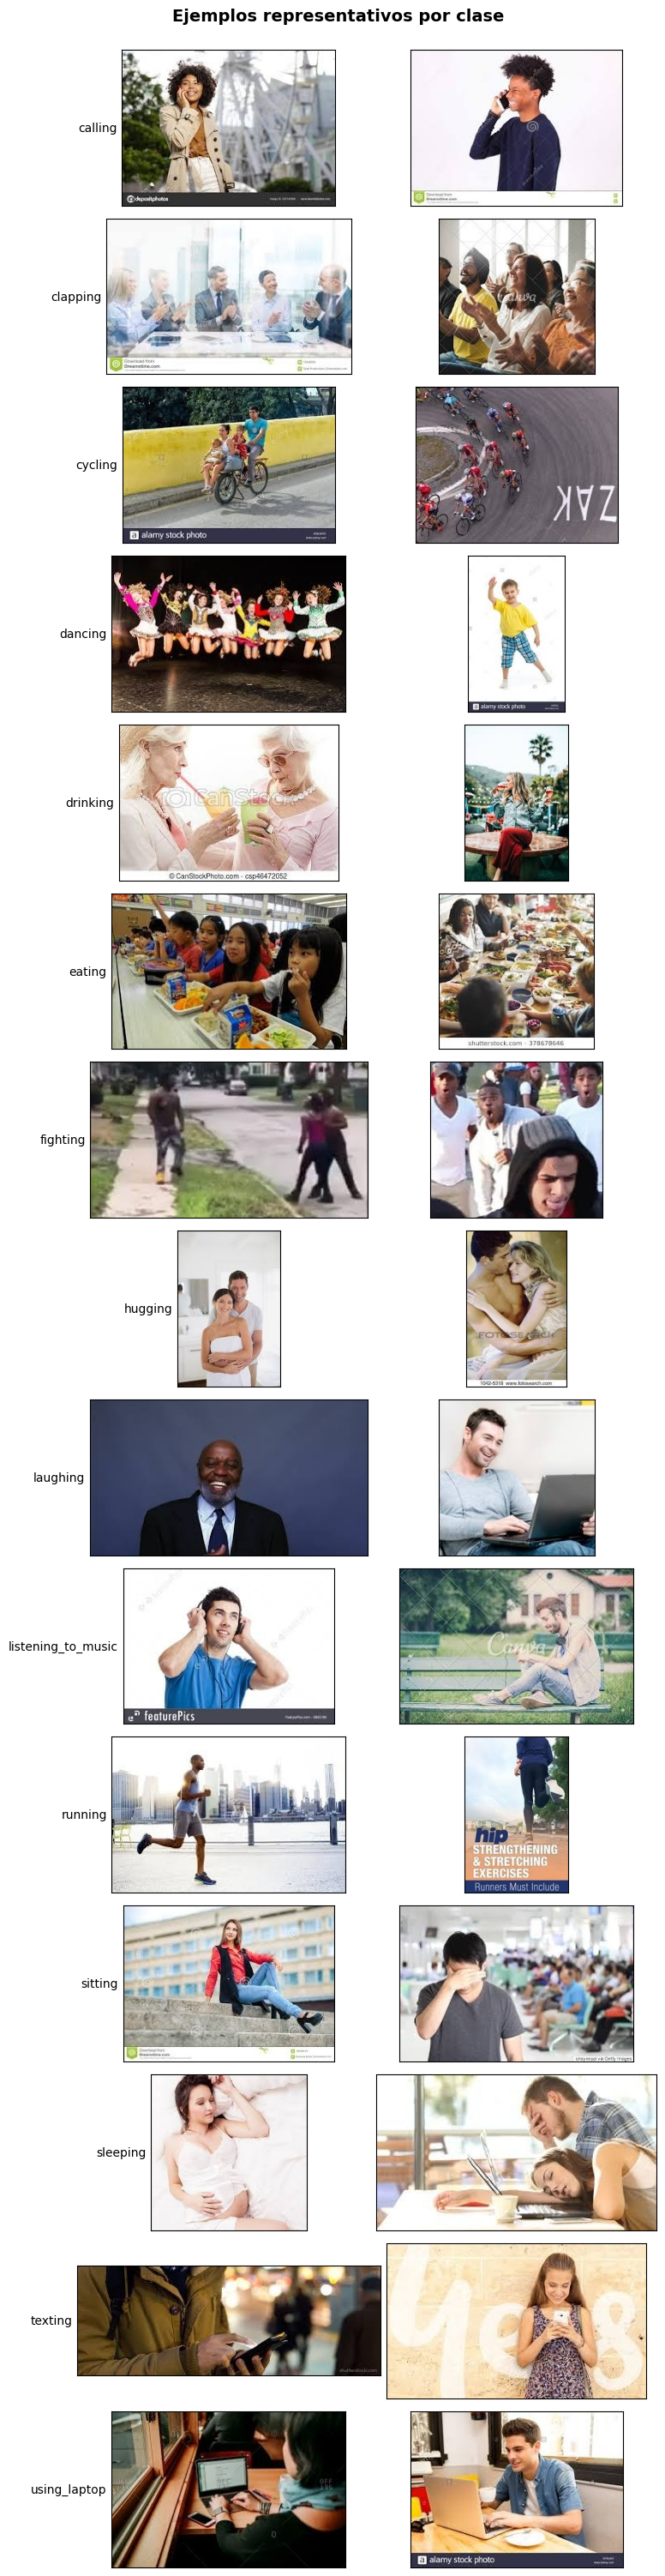

In [27]:
# Mostrar ejemplos representativos de cada clase para identificar
# posibles problemas de calidad, variabilidad o etiquetado.

clases_ordenadas = sorted(y_train.unique())
n_ejemplos_por_clase = 2

fig, axes = plt.subplots(
    len(clases_ordenadas), n_ejemplos_por_clase,
    figsize=(4 * n_ejemplos_por_clase, 2.0 * len(clases_ordenadas))
)

for fila, clase in enumerate(clases_ordenadas):
    archivos_clase = X_train.loc[y_train == clase, "filename"].sample(
        n_ejemplos_por_clase, random_state=SEED
    ).values
    for col, filename in enumerate(archivos_clase):
        ruta_imagen = os.path.join(TRAIN_DIR, filename)
        img = cv2.imread(ruta_imagen)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        ax = axes[fila, col]
        ax.imshow(img_rgb)
        if col == 0:
            ax.set_ylabel(clase, fontsize=10, rotation=0, ha="right", va="center")
        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle("Ejemplos representativos por clase", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()


# 4. Estrategia 1 — CNN desde cero (*from scratch*)

## 4.1 Diseño de la arquitectura inicial

[COMPLETAR: justificar número de bloques convolucionales, filtros, tamaño de kernel, activaciones, pooling y capas finales.]

In [6]:
# COMPLETAR: definir la arquitectura CNN desde cero con TensorFlow/Keras.
# COMPLETAR: mostrar el resumen de la arquitectura.
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras import layers
from sklearn.preprocessing import LabelEncoder

TAMANO_IMAGEN = (128, 128)

imagenes_procesadas = []

for filename in X_train['filename']:
    ruta_completa = os.path.join(ruta_carpeta, filename)
    img = cv2.imread(ruta_completa)
    
    # Verificamos que la imagen se haya leído correctamente
    if img is not None:
        # REDIMENSIONAR: Cambia el tamaño físicamente sin romper la estructura de la imagen
        img_redimensionada = cv2.resize(img, TAMANO_IMAGEN)
        
        # Guardamos en nuestra lista
        imagenes_procesadas.append(img_redimensionada)

X_train_final = np.array(imagenes_procesadas)

print("Forma final del set de datos:", X_train_final.shape)
print("Forma final del set de datos:", y_train.shape)

X_train_final = X_train_final.astype('float32') / 255.0

cnn_HAR = Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    #layers.Dense(128, activation="relu"),
    layers.Dense(15, activation="softmax")
])

cnn_HAR.summary()

Forma final del set de datos: (12600, 128, 128, 3)
Forma final del set de datos: (12600,)


/home/fantr/projects/tensorflow-amd/.venv-rocm/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1794368377.188206   90450 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12421 MB memory:  -> device: 0, name: AMD Radeon RX 9070 XT, pci bus id: 0000:2b:00.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │       864,015 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 883,407 (3.37 MB)

 Trainable params: 883,407 (3.37 MB)

 Non-trainable params: 0 (0.00 B)

## 4.2 Configuración del entrenamiento

- Optimizador: [COMPLETAR]
- Learning rate: [COMPLETAR]
- Batch size: [COMPLETAR]
- Número de épocas: [COMPLETAR]
- Función de pérdida: [COMPLETAR]
- Métricas: [COMPLETAR]
- Callbacks (si se utilizan): [COMPLETAR]

[COMPLETAR: justificar la configuración elegida.]

In [7]:
encoder = LabelEncoder()
y_train_numerico = encoder.fit_transform(y_train)

print("Etiquetas originales:", y_train.values[:5])
print("Etiquetas numéricas:", y_train_numerico[:5])

Etiquetas originales: <StringArray>
['sitting', 'using_laptop', 'hugging', 'sleeping', 'using_laptop']
Length: 5, dtype: str
Etiquetas numéricas: [11 14  7 12 14]


In [ ]:
# COMPLETAR: compilar el modelo.
# COMPLETAR: definir callbacks de monitorización/regularización si procede.
# COMPLETAR: entrenar el modelo y conservar el historial.


cnn_HAR.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history_cnn_HAR = cnn_HAR.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    validation_split=0.1
)


Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 303ms/step - accuracy: 0.8821 - loss: 0.4023 - val_accuracy: 0.2437 - val_loss: 3.9828
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 300ms/step - accuracy: 0.9222 - loss: 0.2867 - val_accuracy: 0.2683 - val_loss: 4.2417
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 298ms/step - accuracy: 0.9399 - loss: 0.2363 - val_accuracy: 0.2675 - val_loss: 4.7474
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 298ms/step - accuracy: 0.9368 - loss: 0.2373 - val_accuracy: 0.2619 - val_loss: 4.5135
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 299ms/step - accuracy: 0.9737 - loss: 0.1273 - val_accuracy: 0.2595 - val_loss: 5.1299
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 298ms/step - accuracy: 0.9879 - loss: 0.0746 - val_accuracy: 0.2468 - val_loss: 5.2704
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 298ms/step - accuracy: 0.9934 - loss: 0.0489 - val_accuracy: 0.2667 - val_loss: 5.5614
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 27s 299ms/step - accuracy: 0.9974 - loss: 0.0311 - val_accu

## 4.3 Monitorización del entrenamiento

[COMPLETAR: representar las curvas de pérdida y métricas de entrenamiento y validación. Interpretar convergencia, sobreajuste o subajuste.]

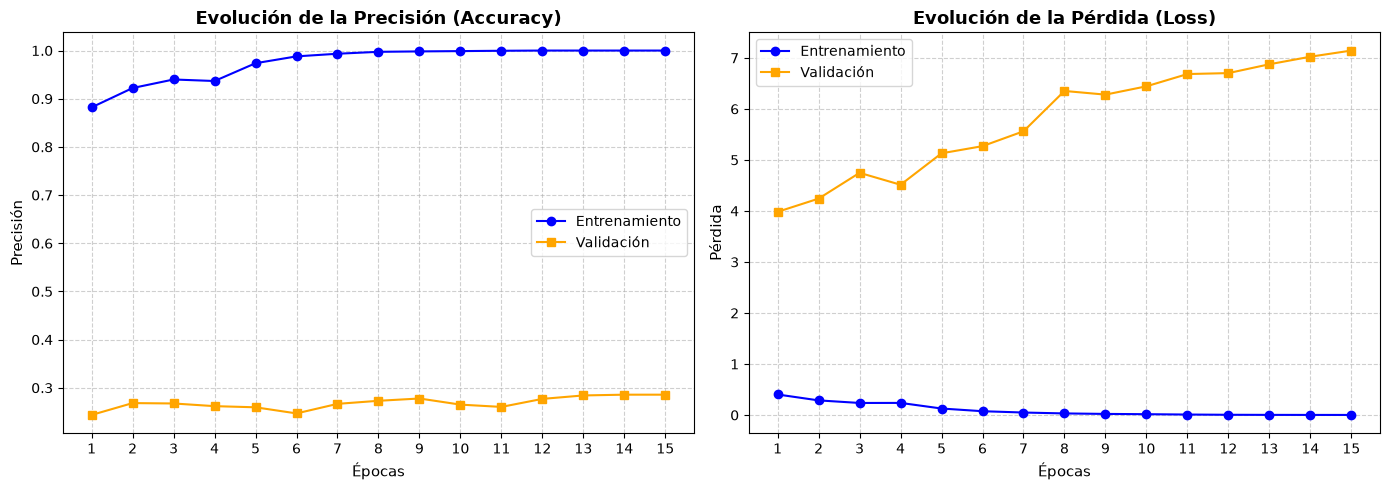

In [13]:
# COMPLETAR: representar las curvas de entrenamiento y validación.

history_dict = history_cnn_HAR.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


## 4.4 Experimentación progresiva y regularización

Realizar experimentos que permitan estudiar el efecto de las decisiones de diseño. Considerar, cuando sea pertinente:

- *Weight regularization*.
- *Dropout*.
- *Batch normalization*.
- *Data augmentation*.
- Cambios en la arquitectura, optimizador o learning rate.

**Experimento 1 — objetivo e hipótesis:** [COMPLETAR]  
**Cambios respecto al experimento anterior:** [COMPLETAR]  
**Resultados observados:** [COMPLETAR]  
**Interpretación y decisión para el siguiente experimento:** [COMPLETAR]

c:\Users\Fantr\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,394,255 (28.21 MB)

 Trainable params: 7,394,255 (28.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 382ms/step - accuracy: 0.1095 - loss: 3.1436 - val_accuracy: 0.1968 - val_loss: 2.6203
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 33s 370ms/step - accuracy: 0.2015 - loss: 2.6227 - val_accuracy: 0.2452 - val_loss: 2.5940
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 33s 373ms/step - accuracy: 0.2486 - loss: 2.5435 - val_accuracy: 0.2659 - val_loss: 2.5174
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 381ms/step - accuracy: 0.2762 - loss: 2.4893 - val_accuracy: 0.2857 - val_loss: 2.4669
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 33s 372ms/step - accuracy: 0.3039 - loss: 2.4299 - val_accuracy: 0.3048 - val_loss: 2.4650
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 33s 372ms/step - accuracy: 0.3273 - loss: 2.3784 - val_accuracy: 0.3317 - val_loss: 2.4220
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 382ms/step - accuracy: 0.3467 - loss: 2.3463 - val_accuracy: 0.3317 - val_loss: 2.4345
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 386ms/step - accuracy: 0.3638 - loss: 2.3132 - val_accu

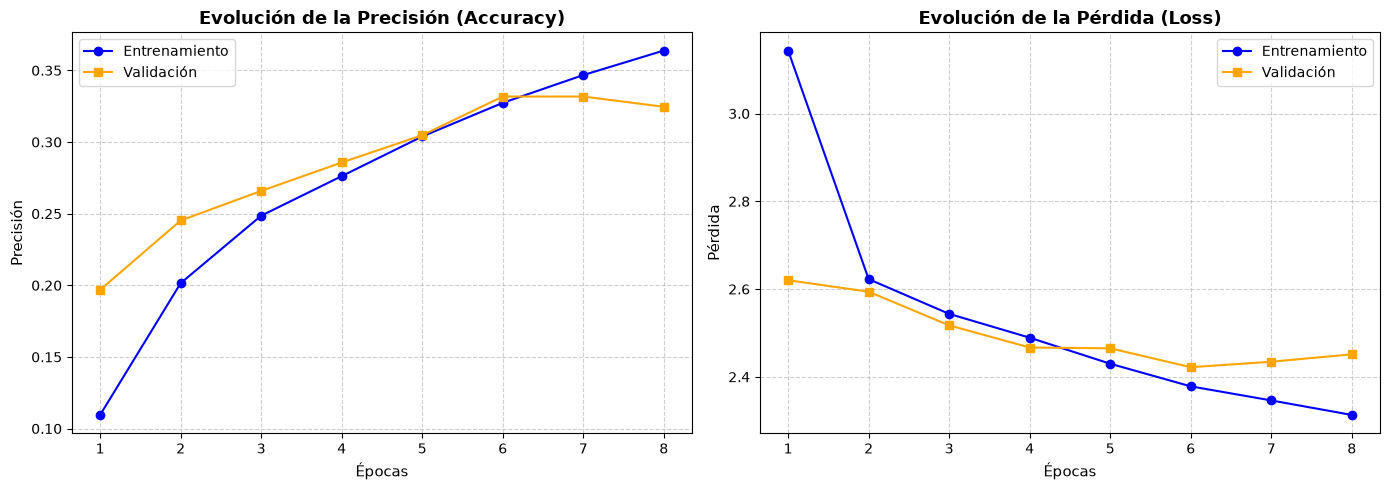

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ #agregue una capa dropout y una extra de densas
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),  # Agregamos Dropout para prevenir overfitting


    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)), # Agregamos regularizadores L2 para prevenir overfitting y estabilidad en la red
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)


cnn_HAR_dropout_dense.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_26 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_13 (Flatten)            │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,394,255 (28.21 MB)

 Trainable params: 7,394,255 (28.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 36s 403ms/step - accuracy: 0.1346 - loss: 3.8542 - val_accuracy: 0.2302 - val_loss: 2.9624
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 395ms/step - accuracy: 0.2391 - loss: 2.7366 - val_accuracy: 0.2659 - val_loss: 2.5769
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 398ms/step - accuracy: 0.2966 - loss: 2.4868 - val_accuracy: 0.2817 - val_loss: 2.4668
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 397ms/step - accuracy: 0.3217 - loss: 2.3751 - val_accuracy: 0.2960 - val_loss: 2.4090
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 37s 418ms/step - accuracy: 0.3464 - loss: 2.2987 - val_accuracy: 0.3103 - val_loss: 2.3685
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 38s 423ms/step - accuracy: 0.3647 - loss: 2.2318 - val_accuracy: 0.3056 - val_loss: 2.3459
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 36s 408ms/step - accuracy: 0.3820 - loss: 2.1834 - val_accuracy: 0.3071 - val_loss: 2.3326
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 394ms/step - accuracy: 0.4003 - loss: 2.1462 - val_accu

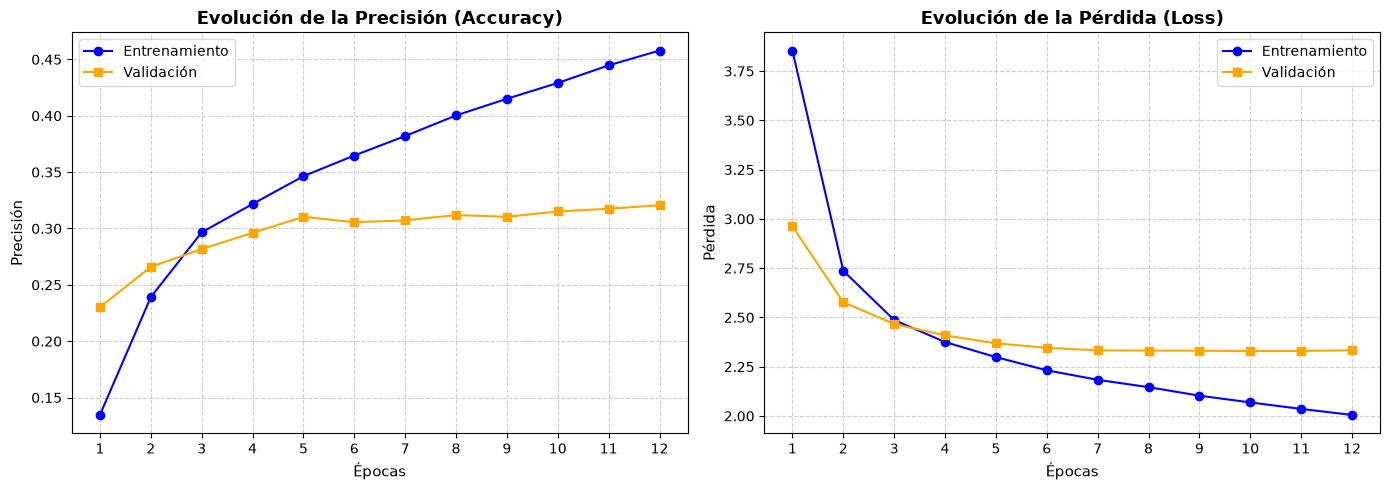

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)),
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

optimizer = Adam(learning_rate=0.0001) # Se agrego un learning rate diferente para el optimizador Adam

cnn_HAR_dropout_dense.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


c:\Users\Fantr\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_14 (Flatten)            │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,394,255 (28.21 MB)

 Trainable params: 7,394,255 (28.21 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 36s 403ms/step - accuracy: 0.0858 - loss: 3.3225 - val_accuracy: 0.1151 - val_loss: 3.0152
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 395ms/step - accuracy: 0.1250 - loss: 2.8880 - val_accuracy: 0.1556 - val_loss: 2.7720
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 398ms/step - accuracy: 0.1707 - loss: 2.6918 - val_accuracy: 0.2032 - val_loss: 2.6070
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 398ms/step - accuracy: 0.2039 - loss: 2.5634 - val_accuracy: 0.2183 - val_loss: 2.5228
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 398ms/step - accuracy: 0.2311 - loss: 2.4748 - val_accuracy: 0.2286 - val_loss: 2.4645
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 36s 399ms/step - accuracy: 0.2468 - loss: 2.4135 - val_accuracy: 0.2389 - val_loss: 2.4194
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 35s 389ms/step - accuracy: 0.2623 - loss: 2.3626 - val_accuracy: 0.2492 - val_loss: 2.3898
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 34s 385ms/step - accuracy: 0.2794 - loss: 2.3216 - val_accu

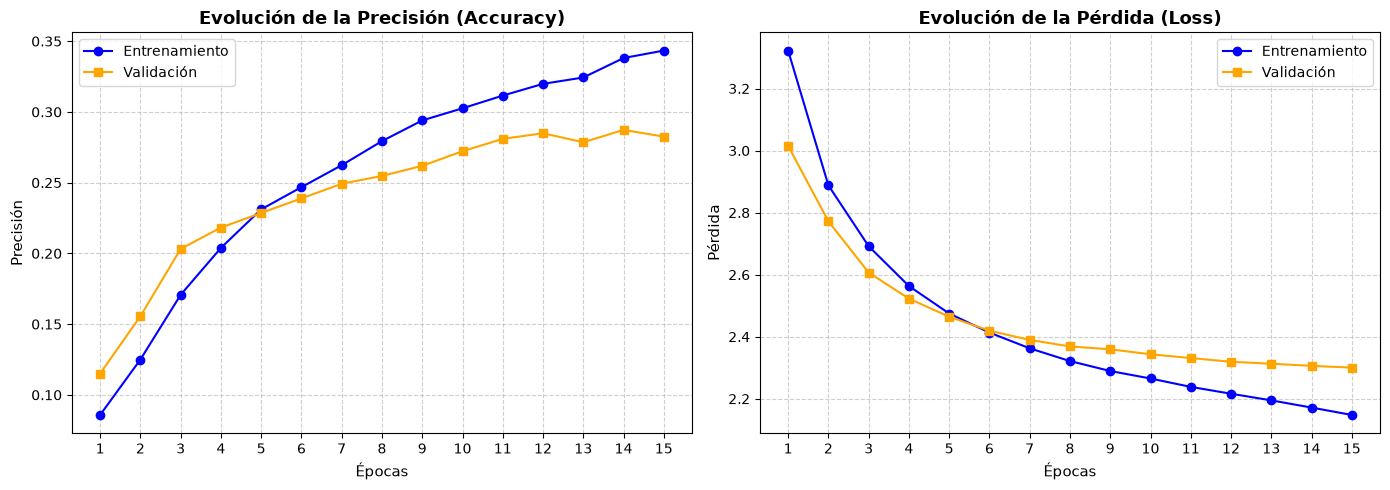

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.004)), # Cambio de tasa para el regularizador
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

optimizer = Adam(learning_rate=0.0001)

cnn_HAR_dropout_dense.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 61, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_32 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,795,407 (25.92 MB)

 Trainable params: 6,795,407 (25.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.1181 - loss: 3.9881 - val_accuracy: 0.1849 - val_loss: 3.0864
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.2030 - loss: 2.8210 - val_accuracy: 0.2556 - val_loss: 2.6235
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.2667 - loss: 2.5270 - val_accuracy: 0.2857 - val_loss: 2.4753
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.2955 - loss: 2.3985 - val_accuracy: 0.3008 - val_loss: 2.3836
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.3183 - loss: 2.3075 - val_accuracy: 0.3119 - val_loss: 2.3235
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.3363 - loss: 2.2371 - val_accuracy: 0.3325 - val_loss: 2.2814
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 122s 1s/step - accuracy: 0.3612 - loss: 2.1730 - val_accuracy: 0.3373 - val_loss: 2.2520
Epoch 8/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.3806 - loss: 2.1192 - val_accuracy: 0.3476 - v

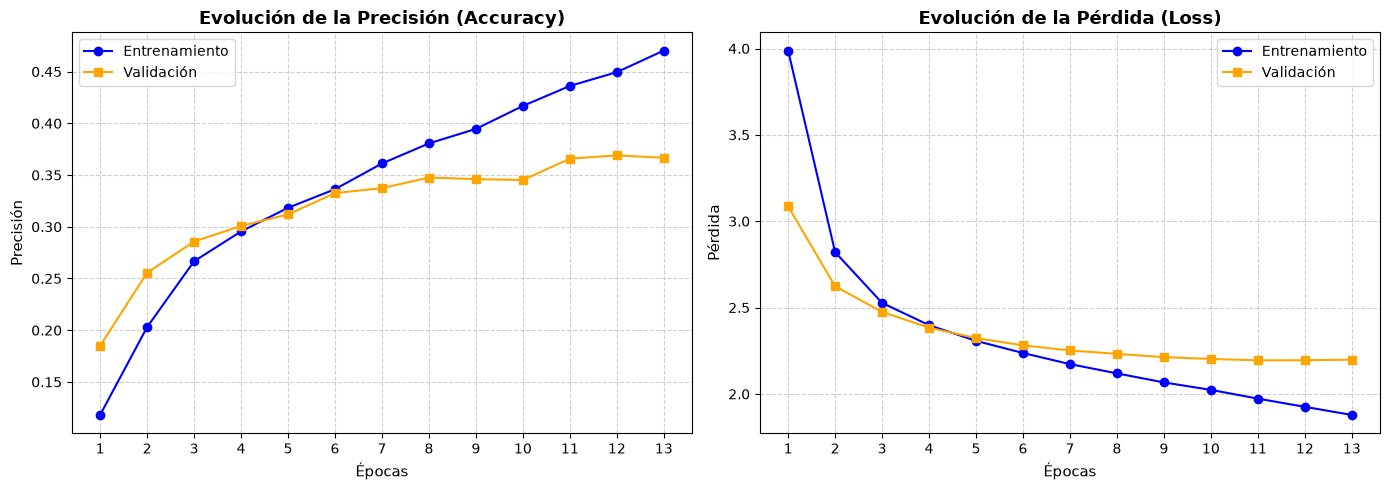

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Conv2D(64, (3, 3), activation="relu", input_shape=(128, 128, 3)), # Aumento de la red de 32 --> 64
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"), # Aumento de la red de 64 --> 128
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), activation="relu"), # Creacion de una nueva capa convolucional para aumentar la capacidad de aprendizaje 256
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)), # Volvemos a la tasa anterior porque obtuvimos peores resultados
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

optimizer = Adam(learning_rate=0.0001)

cnn_HAR_dropout_dense.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_33 (Conv2D)              │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_33 (MaxPooling2D) │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 61, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_34 (MaxPooling2D) │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_35 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_16 (Flatten)            │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,795,407 (25.92 MB)

 Trainable params: 6,795,407 (25.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.0698 - loss: 3.1263 - val_accuracy: 0.1484 - val_loss: 2.6559 - learning_rate: 0.0010
Epoch 2/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.1614 - loss: 2.5881 - val_accuracy: 0.2040 - val_loss: 2.5001 - learning_rate: 0.0010
Epoch 3/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.2152 - loss: 2.4926 - val_accuracy: 0.2381 - val_loss: 2.4528 - learning_rate: 0.0010
Epoch 4/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.2592 - loss: 2.4055 - val_accuracy: 0.2794 - val_loss: 2.3242 - learning_rate: 0.0010
Epoch 5/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.2995 - loss: 2.3109 - val_accuracy: 0.3151 - val_loss: 2.2633 - learning_rate: 0.0010
Epoch 6/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 130s 1s/step - accuracy: 0.3334 - loss: 2.2261 - val_accuracy: 0.3310 - val_loss: 2.2297 - learning_rate: 0.0010
Epoch 7/15
89/89 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.3551 - loss: 2.1754 - val_acc

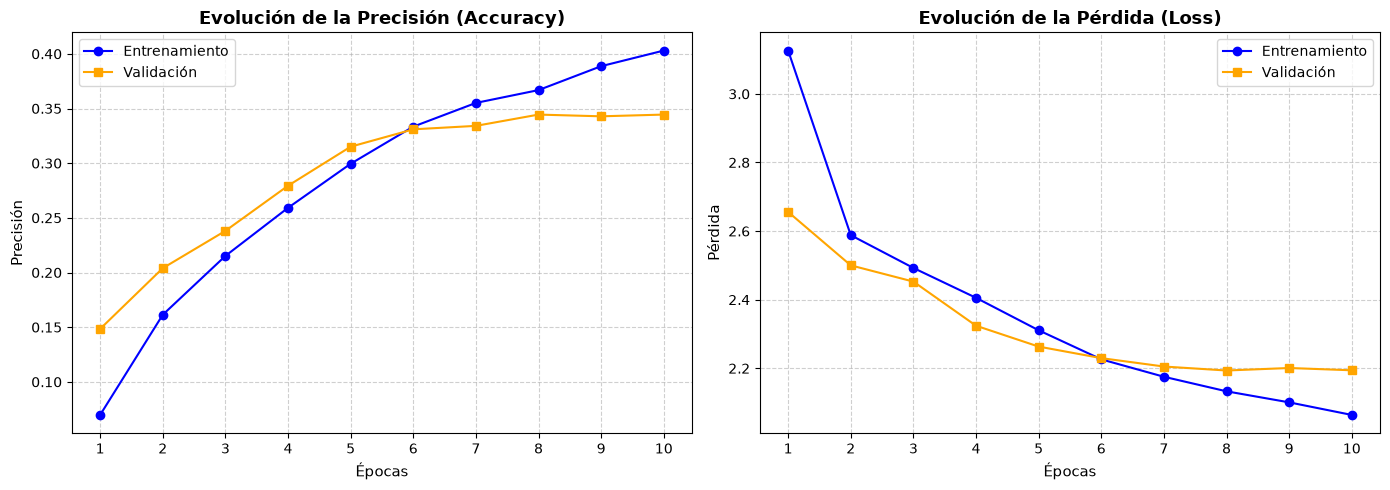

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Conv2D(64, (3, 3), activation="relu", input_shape=(128, 128, 3)), # Aumento de la red de 32 --> 64
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"), # Aumento de la red de 64 --> 128
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), activation="relu"), # Creacion de una nueva capa convolucional para aumentar la capacidad de aprendizaje 256
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)), # Volvemos a la tasa anterior porque obtuvimos peores resultados
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

lr_scheduler = callbacks.ReduceLROnPlateau( # Agregamos un LR Scheduler para mejora dinamica del LR
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

#optimizer = Adam(learning_rate=0.0001)

cnn_HAR_dropout_dense.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=15,
    batch_size=128,
    callbacks=[early_stop, lr_scheduler],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 128)  │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 63, 63, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,313,423 (27.90 MB)

 Trainable params: 7,313,423 (27.90 MB)

 Non-trainable params: 0 (0.00 B)

W0000 00:00:1794368393.875362   90450 cpu_allocator_impl.cc:82] Allocation of 1981808640 exceeds 10% of free system memory.
W0000 00:00:1794368396.258663   90450 cpu_allocator_impl.cc:82] Allocation of 1981808640 exceeds 10% of free system memory.


Epoch 1/60


E0000 00:00:1794368398.501566   90450 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_2_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


79/79 ━━━━━━━━━━━━━━━━━━━━ 26s 186ms/step - accuracy: 0.0708 - loss: 3.2569 - val_accuracy: 0.0925 - val_loss: 2.7954 - learning_rate: 0.0010
Epoch 2/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 173ms/step - accuracy: 0.1157 - loss: 2.7354 - val_accuracy: 0.1421 - val_loss: 2.6437 - learning_rate: 0.0010
Epoch 3/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 171ms/step - accuracy: 0.1454 - loss: 2.6461 - val_accuracy: 0.1587 - val_loss: 2.5942 - learning_rate: 0.0010
Epoch 4/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 175ms/step - accuracy: 0.1731 - loss: 2.5840 - val_accuracy: 0.1440 - val_loss: 2.6613 - learning_rate: 0.0010
Epoch 5/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 172ms/step - accuracy: 0.2002 - loss: 2.5176 - val_accuracy: 0.1718 - val_loss: 2.6296 - learning_rate: 0.0010
Epoch 6/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 185ms/step - accuracy: 0.2229 - loss: 2.4414 - val_accuracy: 0.2024 - val_loss: 2.5280 - learning_rate: 0.0010
Epoch 7/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 189ms/step - accuracy: 0.2464 - loss: 2.3675 - val_

W0000 00:00:1794369053.922114   91354 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 25166848 bytes after encountering the first element of size 25166848 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 187ms/step - accuracy: 0.3649 - loss: 2.0729 - val_accuracy: 0.3667 - val_loss: 2.1202 - learning_rate: 0.0010
Epoch 46/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 15s 188ms/step - accuracy: 0.3660 - loss: 2.0689 - val_accuracy: 0.3448 - val_loss: 2.2086 - learning_rate: 0.0010
Epoch 47/60
79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 181ms/step - accuracy: 0.3664 - loss: 2.0643 - val_accuracy: 0.3619 - val_loss: 2.1320 - learning_rate: 0.0010


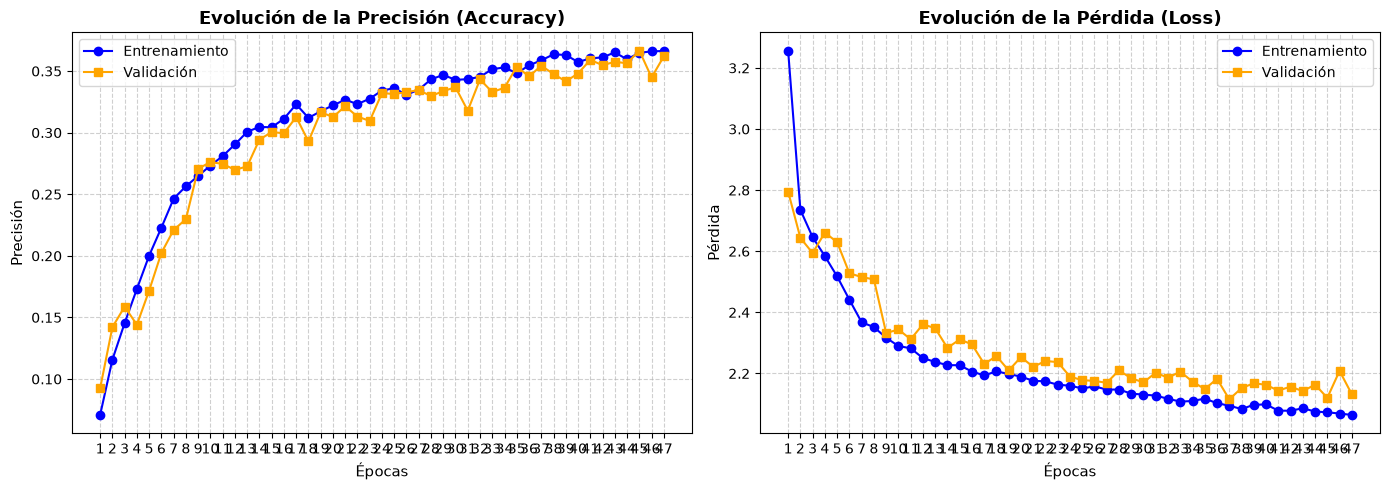

In [8]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

data_augmentation = Sequential([ # Implementando data augmentation para mas variedad de imagenes en el dataset
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Input(shape=(128, 128, 3)), #Nueva capa Input al inicio de la red

    data_augmentation,

    layers.Conv2D(128, (3, 3), activation="relu"), # Aumento de la red de 64 --> 128
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), activation="relu"), # Aumento de la red de 128 --> 256
    layers.MaxPooling2D((2, 2)),
    #layers.Dropout(0.3),

    layers.Conv2D(256, (3, 3), activation="relu"), # Creacion de una nueva capa convolucional para aumentar la capacidad de aprendizaje 256
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(128, activation="relu",kernel_regularizer=regularizers.l2(0.01)), # Volvemos a la tasa anterior porque obtuvimos peores resultados
    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

lr_scheduler = callbacks.ReduceLROnPlateau( # Agregamos un LR Scheduler para mejora dinamica del LR
    monitor='val_loss',
    factor=0.2,
    patience=10, # Aumento de la paciencia por el data augmentation
    min_lr=0.001,
    verbose=1
)

optimizer = Adam(learning_rate=0.001)

cnn_HAR_dropout_dense.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=60, # Aumento de epocas por el data augmentation
    batch_size=128,
    callbacks=[early_stop, lr_scheduler],
    validation_split=0.2,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


/home/fantr/projects/tensorflow-amd/.venv-rocm/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 61, 61, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,795,407 (25.92 MB)

 Trainable params: 6,795,407 (25.92 MB)

 Non-trainable params: 0 (0.00 B)

W0000 00:00:1794369134.972421   90450 cpu_allocator_impl.cc:82] Allocation of 2229534720 exceeds 10% of free system memory.
W0000 00:00:1794369137.980128   90450 cpu_allocator_impl.cc:82] Allocation of 2229534720 exceeds 10% of free system memory.


Epoch 1/50


E0000 00:00:1794369140.216149   90450 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_4_1/dropout_2_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1794369140.398541   91262 rocm_solvers.cc:127] Creating GpuSolver handles for stream 0x697eea80


89/89 ━━━━━━━━━━━━━━━━━━━━ 17s 151ms/step - accuracy: 0.1007 - loss: 3.9499 - val_accuracy: 0.1683 - val_loss: 3.0526
Epoch 2/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 147ms/step - accuracy: 0.1805 - loss: 2.8083 - val_accuracy: 0.2333 - val_loss: 2.6083
Epoch 3/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 147ms/step - accuracy: 0.2252 - loss: 2.5560 - val_accuracy: 0.2619 - val_loss: 2.4567
Epoch 4/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 144ms/step - accuracy: 0.2568 - loss: 2.4508 - val_accuracy: 0.2841 - val_loss: 2.3875
Epoch 5/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 148ms/step - accuracy: 0.2706 - loss: 2.3876 - val_accuracy: 0.2897 - val_loss: 2.3363
Epoch 6/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 145ms/step - accuracy: 0.2862 - loss: 2.3399 - val_accuracy: 0.3175 - val_loss: 2.2986
Epoch 7/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 147ms/step - accuracy: 0.2970 - loss: 2.3080 - val_accuracy: 0.3151 - val_loss: 2.2760
Epoch 8/50
89/89 ━━━━━━━━━━━━━━━━━━━━ 13s 146ms/step - accuracy: 0.3009 - loss: 2.2786 - val_accuracy: 0.323

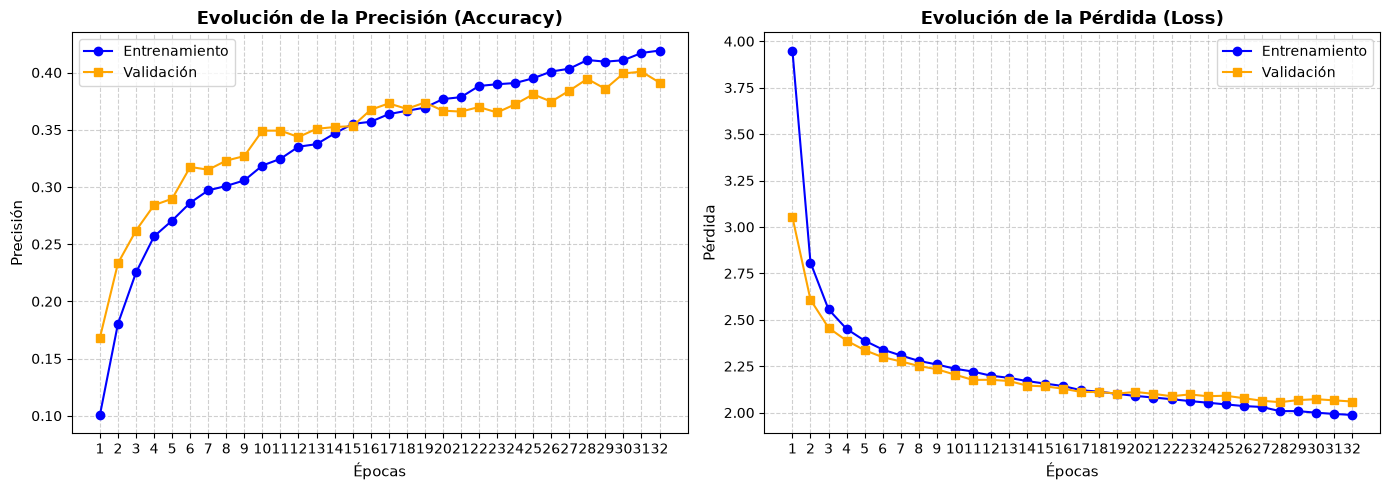

In [ ]:
# COMPLETAR: implementar y ejecutar experimentos adicionales.
# Mantener un registro de configuración y resultados de cada experimento.
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models, regularizers, callbacks
from tensorflow.keras.optimizers import Adam

data_augmentation = Sequential([ # Implementando data augmentation para mas variedad de imagenes en el dataset
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

cnn_HAR_dropout_dense = Sequential([ # Agregue una capa dropout y una extra de densas
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.Conv2D(128, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.Conv2D(256, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(512, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.Conv2D(512, (3, 3), padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(256, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),
    layers.Dropout(0.4),
    layers.Dense(256, use_bias=False, kernel_regularizer=regularizers.l2(0.01)),
    layers.BatchNormalization(),
    layers.LeakyReLU(negative_slope=0.01),

    layers.Dense(15, activation="softmax")
])

cnn_HAR_dropout_dense.summary()
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

optimizer = Adam(learning_rate=0.0001)

cnn_HAR_dropout_dense.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)

history_cnn_HAR_dropout_dense = cnn_HAR_dropout_dense.fit(
    X_train_final,
    y_train_numerico,
    epochs=50,
    batch_size=128,
    callbacks=[early_stop],
    validation_split=0.1,
    
)

history_dict = history_cnn_HAR_dropout_dense.history
epochs = range(1, len(history_dict["accuracy"]) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(
    epochs, history_dict["accuracy"], "o-", label="Entrenamiento", color="blue"
)
ax1.plot(
    epochs,
    history_dict["val_accuracy"],
    "s-",
    label="Validación",
    color="orange",
)
ax1.set_title("Evolución de la Precisión (Accuracy)", fontsize=13, weight="bold")
ax1.set_xlabel("Épocas", fontsize=11)
ax1.set_ylabel("Precisión", fontsize=11)
ax1.set_xticks(epochs)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs, history_dict["loss"], "o-", label="Entrenamiento", color="blue")
ax2.plot(
    epochs, history_dict["val_loss"], "s-", label="Validación", color="orange"
)
ax2.set_title(
    "Evolución de la Pérdida (Loss)", fontsize=13, weight="bold"
)
ax2.set_xlabel("Épocas", fontsize=11)
ax2.set_ylabel("Pérdida", fontsize=11)
ax2.set_xticks(epochs)
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


## 4.5 Selección del modelo *from scratch*

[COMPLETAR: identificar el modelo seleccionado y justificarlo a partir de los resultados de validación y del comportamiento durante el entrenamiento.]

In [ ]:
# COMPLETAR: recuperar/cargar el modelo seleccionado para la evaluación final.


# 5. Estrategia 2 — Modelos preentrenados

Se deberán comparar **al menos dos arquitecturas CNN preentrenadas sobre ImageNet**. Para cada una, documentar *transfer learning* y *fine-tuning*, además de los experimentos realizados.

## 5.1 Decisiones comunes

- Resolución de entrada: [COMPLETAR]
- Preprocesamiento específico de cada arquitectura: [COMPLETAR]
- Pesos iniciales: [COMPLETAR]
- Estrategia para congelar/descongelar capas: [COMPLETAR]
- Clasificador final: [COMPLETAR]
- Regularización y *data augmentation*: [COMPLETAR]

[COMPLETAR: justificar las decisiones comunes y las diferencias entre arquitecturas.]

## 5.2 Arquitectura preentrenada 1 — [NOMBRE]

### Selección y descripción

[COMPLETAR: nombre, características relevantes y justificación de la elección.]

### Fase A — Transfer learning

[COMPLETAR: indicar qué capas permanecen congeladas, cómo se entrena el clasificador y por qué.]

In [ ]:
# COMPLETAR: cargar la arquitectura preentrenada con pesos ImageNet.
# COMPLETAR: adaptar la parte clasificadora al número de clases.
# COMPLETAR: mostrar el resumen del modelo.


In [ ]:
# COMPLETAR: compilar y entrenar la fase de transfer learning.
# COMPLETAR: conservar el historial de entrenamiento.


### Monitorización de transfer learning

[COMPLETAR: representar e interpretar las curvas y métricas.]

In [ ]:
# COMPLETAR: representar las curvas de entrenamiento y validación.


### Fase B — Fine-tuning

[COMPLETAR: explicar qué capas se descongelan, si se hace progresivamente y qué learning rate se utiliza.]

In [ ]:
# COMPLETAR: configurar el fine-tuning, recompilar y entrenar.
# COMPLETAR: guardar el historial y el modelo resultante.


### Análisis de la arquitectura

[COMPLETAR: comparar transfer learning frente a fine-tuning y justificar la configuración seleccionada.]

## 5.3 Arquitectura preentrenada 2 — [NOMBRE]

### Selección y descripción

[COMPLETAR: nombre, características relevantes y justificación de la elección.]

### Fase A — Transfer learning

[COMPLETAR: indicar qué capas permanecen congeladas, cómo se entrena el clasificador y por qué.]

In [ ]:
# COMPLETAR: cargar la arquitectura preentrenada con pesos ImageNet.
# COMPLETAR: adaptar la parte clasificadora al número de clases.
# COMPLETAR: mostrar el resumen del modelo.


In [ ]:
# COMPLETAR: compilar y entrenar la fase de transfer learning.
# COMPLETAR: conservar el historial de entrenamiento.


### Monitorización de transfer learning

[COMPLETAR: representar e interpretar las curvas y métricas.]

In [ ]:
# COMPLETAR: representar las curvas de entrenamiento y validación.


### Fase B — Fine-tuning

[COMPLETAR: explicar qué capas se descongelan, si se hace progresivamente y qué learning rate se utiliza.]

In [ ]:
# COMPLETAR: configurar el fine-tuning, recompilar y entrenar.
# COMPLETAR: guardar el historial y el modelo resultante.


### Análisis de la arquitectura

[COMPLETAR: comparar transfer learning frente a fine-tuning y justificar la configuración seleccionada.]

## 5.4 Comparación de arquitecturas preentrenadas

[COMPLETAR: comparar ambas arquitecturas con las mismas particiones y métricas. Analizar rendimiento, coste computacional y generalización.]

In [ ]:
# COMPLETAR: preparar una tabla comparativa con los resultados de las
# arquitecturas preentrenadas y sus variantes (transfer learning/fine-tuning).


# 6. Evaluación y comparación global de estrategias

## 6.1 Evaluación final sobre test

[COMPLETAR: evaluar únicamente los modelos seleccionados sobre el conjunto de test. No utilizar test para tomar decisiones durante el entrenamiento.]

In [ ]:
# COMPLETAR: evaluar el modelo from scratch sobre test.
# COMPLETAR: evaluar los modelos preentrenados seleccionados sobre test.
# COMPLETAR: registrar las métricas generadas durante la ejecución.


## 6.2 Métricas y análisis por clase

[COMPLETAR: incluir métricas apropiadas para el problema. Considerar matriz de confusión, precision, recall, F1-score y métricas por clase cuando proceda.]

In [ ]:
# COMPLETAR: generar matrices de confusión y métricas por clase.
# COMPLETAR: generar las visualizaciones correspondientes.


## 6.3 Comparación de resultados

Comparar, como mínimo:

- Rendimiento sobre el conjunto de test.
- Evolución del entrenamiento y validación.
- Capacidad de generalización.
- Evidencias de sobreajuste o subajuste.
- Tiempo/coste de entrenamiento, si se ha medido.
- Ventajas e inconvenientes de cada estrategia.

**Análisis:** [COMPLETAR]

In [ ]:
# COMPLETAR: construir una tabla o visualización comparativa final
# con métricas obtenidas durante la ejecución.


## 6.4 Errores y ejemplos de predicción

[COMPLETAR: inspeccionar ejemplos correctamente e incorrectamente clasificados. Analizar patrones de error y posibles causas.]

In [ ]:
# COMPLETAR: visualizar ejemplos de predicciones y errores del modelo.


# 7. Conclusiones

## 7.1 Mejor modelo y estrategia

[COMPLETAR: indicar qué modelo ofrece la mejor solución y justificar la elección con resultados de test y evidencias experimentales.]

## 7.2 Aprendizajes y análisis crítico

[COMPLETAR: explicar qué decisiones tuvieron mayor impacto, qué técnicas ayudaron o no y qué limitaciones se encontraron.]

## 7.3 Posibles mejoras futuras

[COMPLETAR]

# 8. Referencias

[COMPLETAR: incluir referencias al dataset, documentación de TensorFlow/Keras, artículos y recursos utilizados.]

# 9. Lista de comprobación y exportación a PDF

Antes de entregar:

- [ ] Todas las secciones están completadas.
- [ ] El código se ha ejecutado y no quedan errores.
- [ ] Se muestran evidencias de entrenamiento real para todos los modelos presentados.
- [ ] Las métricas y figuras proceden de la ejecución del notebook.
- [ ] El conjunto de test se ha reservado para la evaluación final.
- [ ] Las conclusiones están respaldadas por los experimentos.
- [ ] El PDF incluye explicaciones, código ejecutado, resultados y figuras.

**Exportación:** generar el PDF directamente desde el notebook de Colab, de modo que se incluyan las celdas y sus salidas. La conversión mediante `nbconvert` puede requerir dependencias LaTeX adicionales.

In [ ]:
# COMPLETAR: si se desea automatizar la exportación a PDF desde Colab,
# configurar aquí las rutas y comandos necesarios.
